In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.9.6 (default, Aug 16 2021, 12:43:27) 
[Clang 12.0.0 ]
Python executable: /opt/anaconda3/envs/walert39/bin/python


In [2]:
import numpy
import pandas
import ranx

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Ranx imported successfully")

NumPy: 1.24.3
Pandas: 2.0.3
Ranx imported successfully


In [3]:
import pandas as pd

topics = pd.read_csv("data/topics.csv")
collection = pd.read_csv("data/collection.csv")
groundtruth = pd.read_csv("data/groundtruth.csv")

print("Topics:", topics.shape)
print("Collection:", collection.shape)
print("Groundtruth:", groundtruth.shape)

Topics: (106, 4)
Collection: (120, 2)
Groundtruth: (140, 5)


In [4]:
display(topics.head())
display(collection.head())
display(groundtruth.head())

,topic_id,topic,question_id,question
0,W01,what's the difference between CS and SE programs?,W01Q01,What sets apart CS programs from SE programs?
1,W01,what's the difference between CS and SE programs?,W01Q02,How do CS and SE programs differ from each other?
2,W01,what's the difference between CS and SE programs?,W01Q03,Can you explain the variances between CS and S...
3,W01,what's the difference between CS and SE programs?,W01Q04,what's the difference between CS and SE programs?
4,W02,What choice of electives available?,W02Q01,Can you describe the range of electives that a...


,passage_id,passage
0,P01,The first two years of these two programs are ...
1,P02,"In the initial two years, the Software Enginee..."
2,P03,The first two years of both Software Engineeri...
3,P04,The Software Engineering and Computer Science ...
4,P05,The initial two years in both Software Enginee...


,topic_id,topic,passage_id,passage,relevance_judgment
0,W01,what's the difference between CS and SE programs?,P01,The first two years of these two programs are ...,2
1,W01,what's the difference between CS and SE programs?,P02,"In the initial two years, the Software Enginee...",2
2,W01,what's the difference between CS and SE programs?,P03,The first two years of both Software Engineeri...,2
3,W01,what's the difference between CS and SE programs?,P04,The Software Engineering and Computer Science ...,2
4,W01,what's the difference between CS and SE programs?,P05,The initial two years in both Software Enginee...,2


In [5]:
qrels = pd.read_csv(
    "data/qrels.txt",
    sep="\t",
    names=["question_id", "zero", "passage_id", "relevance"],
    header=None
)

print("Number of relevance judgments:", len(qrels))
display(qrels.head(10))

Number of relevance judgments: 500


,question_id,zero,passage_id,relevance
0,W01Q01,0,P01,2
1,W01Q01,0,P02,2
2,W01Q01,0,P03,2
3,W01Q01,0,P04,2
4,W01Q01,0,P05,2
5,W01Q01,0,P06,2
6,W01Q02,0,P01,2
7,W01Q02,0,P02,2
8,W01Q02,0,P03,2
9,W01Q02,0,P04,2


In [6]:
bm25 = pd.read_csv(
    "target/runs/rag-bm25.txt",
    sep=r"\s+",
    names=["query_id", "Q0", "passage_id", "rank", "score", "run"],
    header=None
)

dense = pd.read_csv(
    "target/runs/rag-dense-faiss.txt",
    sep=r"\s+",
    names=["query_id", "Q0", "passage_id", "rank", "score", "run"],
    header=None
)

print("BM25 results:", bm25.shape)
print("Dense results:", dense.shape)

BM25 results: (7099, 6)
Dense results: (10600, 6)


In [7]:
display(bm25.head(10))
display(dense.head(10))

,query_id,Q0,passage_id,rank,score,run
0,W01Q01,Q0,P67,1,4.823300,walert.rag.bm25
1,W01Q01,Q0,P35,2,4.791800,walert.rag.bm25
2,W01Q01,Q0,P01,3,4.163400,walert.rag.bm25
3,W01Q01,Q0,P10,4,3.493500,walert.rag.bm25
4,W01Q01,Q0,P120,5,3.150900,walert.rag.bm25
5,W01Q01,Q0,P41,6,3.129200,walert.rag.bm25
6,W01Q01,Q0,P40,7,3.106500,walert.rag.bm25
7,W01Q01,Q0,P42,8,3.106499,walert.rag.bm25
8,W01Q01,Q0,P39,9,3.084200,walert.rag.bm25
9,W01Q01,Q0,P38,10,3.040500,walert.rag.bm25


,query_id,Q0,passage_id,rank,score,run
0,W01Q01,Q0,P42,1,69.156845,walert.rag.dense.faiss
1,W01Q01,Q0,P67,2,69.117035,walert.rag.dense.faiss
2,W01Q01,Q0,P01,3,68.806404,walert.rag.dense.faiss
3,W01Q01,Q0,P41,4,68.596123,walert.rag.dense.faiss
4,W01Q01,Q0,P37,5,68.453239,walert.rag.dense.faiss
5,W01Q01,Q0,P38,6,68.432518,walert.rag.dense.faiss
6,W01Q01,Q0,P40,7,68.258087,walert.rag.dense.faiss
7,W01Q01,Q0,P114,8,67.933556,walert.rag.dense.faiss
8,W01Q01,Q0,P39,9,67.831764,walert.rag.dense.faiss
9,W01Q01,Q0,P120,10,67.542755,walert.rag.dense.faiss


In [8]:
!python src/retrieval/eval.py known data/qrels.txt target/runs/rag-bm25.txt target/runs/rag-dense-faiss.txt

known Topics
#    Model                     NDCG@1    NDCG@3    NDCG@5
---  ----------------------  --------  --------  --------
a    walert.rag.bm25           0.5119    0.4912    0.4733
b    walert.rag.dense.faiss    0.6905    0.6119    0.5812
% Add in preamble
\usepackage{graphicx}
\usepackage{booktabs}


% To change the table size, act on the resizebox argument `0.8`.
\begin{table*}[ht]
\centering
\caption{
Overall effectiveness of the models.
The best results are highlighted in boldface.
Superscripts denote significant differences in Tukey's HSD test with $p \le 0.01$.
}
\resizebox{0.8\textwidth}{!}{
\begin{tabular}{c|l|c|c|c}
\toprule
\textbf{\#}
& \textbf{Model}
& \textbf{NDCG@1}
& \textbf{NDCG@3}
& \textbf{NDCG@5} \\ 
\midrule
a &
walert.rag.bm25 &
0.5119\hphantom{$^{b}$} &
0.4912\hphantom{$^{b}$} &
0.4733\hphantom{$^{b}$} \\
b &
walert.rag.dense.faiss &
\textbf{0.6905}\hphantom{$^{a}$} &
\textbf{0.6119}\hphantom{$^{a}$} &
\textbf{0.5812}\hphantom{$^{a}$} \\
\bottomrule
\end{tab

In [9]:
!python src/retrieval/eval.py inferred data/qrels.txt target/runs/rag-bm25.txt target/runs/rag-dense-faiss.txt

inferred Topics
#    Model                     NDCG@1    NDCG@3    NDCG@5
---  ----------------------  --------  --------  --------
a    walert.rag.bm25           0.1667    0.2566    0.3291
b    walert.rag.dense.faiss    0.25      0.238     0.238
% Add in preamble
\usepackage{graphicx}
\usepackage{booktabs}


% To change the table size, act on the resizebox argument `0.8`.
\begin{table*}[ht]
\centering
\caption{
Overall effectiveness of the models.
The best results are highlighted in boldface.
Superscripts denote significant differences in Tukey's HSD test with $p \le 0.01$.
}
\resizebox{0.8\textwidth}{!}{
\begin{tabular}{c|l|c|c|c}
\toprule
\textbf{\#}
& \textbf{Model}
& \textbf{NDCG@1}
& \textbf{NDCG@3}
& \textbf{NDCG@5} \\ 
\midrule
a &
walert.rag.bm25 &
0.1667\hphantom{$^{b}$} &
\textbf{0.2566}\hphantom{$^{b}$} &
\textbf{0.3291}\hphantom{$^{b}$} \\
b &
walert.rag.dense.faiss &
\textbf{0.2500}\hphantom{$^{a}$} &
0.2380\hphantom{$^{a}$} &
0.2380\hphantom{$^{a}$} \\
\bottomrule
\end{t

In [10]:
results = pd.DataFrame({
    "Topic Set": [
        "Known", "Known",
        "Inferred", "Inferred"
    ],
    "Model": [
        "BM25", "Dense/DPR",
        "BM25", "Dense/DPR"
    ],
    "NDCG@1": [
        0.5119, 0.6905,
        0.1667, 0.2500
    ],
    "NDCG@3": [
        0.4912, 0.6119,
        0.2566, 0.2380
    ],
    "NDCG@5": [
        0.4733, 0.5812,
        0.3291, 0.2380
    ]
})

results

,Topic Set,Model,NDCG@1,NDCG@3,NDCG@5
0,Known,BM25,0.5119,0.4912,0.4733
1,Known,Dense/DPR,0.6905,0.6119,0.5812
2,Inferred,BM25,0.1667,0.2566,0.3291
3,Inferred,Dense/DPR,0.2500,0.2380,0.2380


In [11]:
paper_results = pd.DataFrame({
    "Topic Set": [
        "Known", "Known",
        "Inferred", "Inferred"
    ],
    "Model": [
        "BM25", "Dense/DPR",
        "BM25", "Dense/DPR"
    ],
    "Paper NDCG@1": [
        0.512, 0.691,
        0.167, 0.250
    ],
    "Paper NDCG@3": [
        0.491, 0.612,
        0.256, 0.235
    ],
    "Paper NDCG@5": [
        0.473, 0.581,
        0.329, 0.235
    ]
})

paper_results

,Topic Set,Model,Paper NDCG@1,Paper NDCG@3,Paper NDCG@5
0,Known,BM25,0.512,0.491,0.473
1,Known,Dense/DPR,0.691,0.612,0.581
2,Inferred,BM25,0.167,0.256,0.329
3,Inferred,Dense/DPR,0.250,0.235,0.235


# Comparison with Walert Paper

The reproduced results are compared with the retrieval results
reported in the Walert paper.

In [12]:
comparison = pd.DataFrame({
    "Topic Set": ["Known", "Known", "Inferred", "Inferred"],
    "Model": ["BM25", "Dense/DPR", "BM25", "Dense/DPR"],
    
    "Our NDCG@1": [0.5119, 0.6905, 0.1667, 0.2500],
    "Paper NDCG@1": [0.512, 0.691, 0.167, 0.250],
    
    "Our NDCG@3": [0.4912, 0.6119, 0.2566, 0.2380],
    "Paper NDCG@3": [0.491, 0.612, 0.256, 0.235],
    
    "Our NDCG@5": [0.4733, 0.5812, 0.3291, 0.2380],
    "Paper NDCG@5": [0.473, 0.581, 0.329, 0.235]
})

comparison

,Topic Set,Model,Our NDCG@1,Paper NDCG@1,Our NDCG@3,Paper NDCG@3,Our NDCG@5,Paper NDCG@5
0,Known,BM25,0.5119,0.512,0.4912,0.491,0.4733,0.473
1,Known,Dense/DPR,0.6905,0.691,0.6119,0.612,0.5812,0.581
2,Inferred,BM25,0.1667,0.167,0.2566,0.256,0.3291,0.329
3,Inferred,Dense/DPR,0.2500,0.250,0.2380,0.235,0.2380,0.235


In [13]:
comparison["Difference @1"] = (
    comparison["Our NDCG@1"] - comparison["Paper NDCG@1"]
)

comparison["Difference @3"] = (
    comparison["Our NDCG@3"] - comparison["Paper NDCG@3"]
)

comparison["Difference @5"] = (
    comparison["Our NDCG@5"] - comparison["Paper NDCG@5"]
)

comparison

,Topic Set,Model,Our NDCG@1,Paper NDCG@1,Our NDCG@3,Paper NDCG@3,Our NDCG@5,Paper NDCG@5,Difference @1,Difference @3,Difference @5
0,Known,BM25,0.5119,0.512,0.4912,0.491,0.4733,0.473,-0.0001,0.0002,0.0003
1,Known,Dense/DPR,0.6905,0.691,0.6119,0.612,0.5812,0.581,-0.0005,-0.0001,0.0002
2,Inferred,BM25,0.1667,0.167,0.2566,0.256,0.3291,0.329,-0.0003,0.0006,0.0001
3,Inferred,Dense/DPR,0.2500,0.250,0.2380,0.235,0.2380,0.235,0.0000,0.0030,0.0030


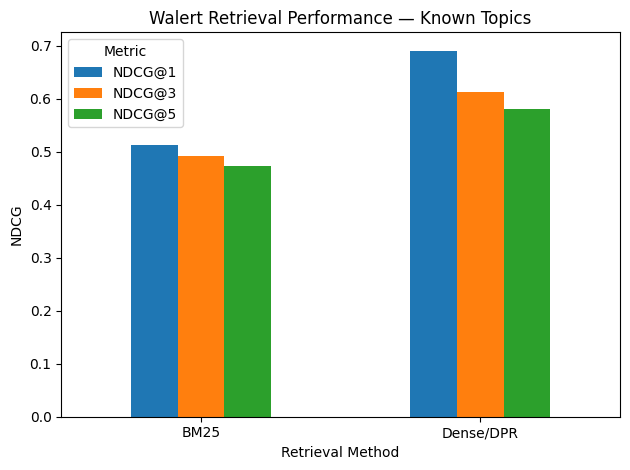

In [14]:
import matplotlib.pyplot as plt

known = results[results["Topic Set"] == "Known"]

known_plot = known.set_index("Model")[["NDCG@1", "NDCG@3", "NDCG@5"]]

known_plot.plot(kind="bar")

plt.title("Walert Retrieval Performance — Known Topics")
plt.xlabel("Retrieval Method")
plt.ylabel("NDCG")
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

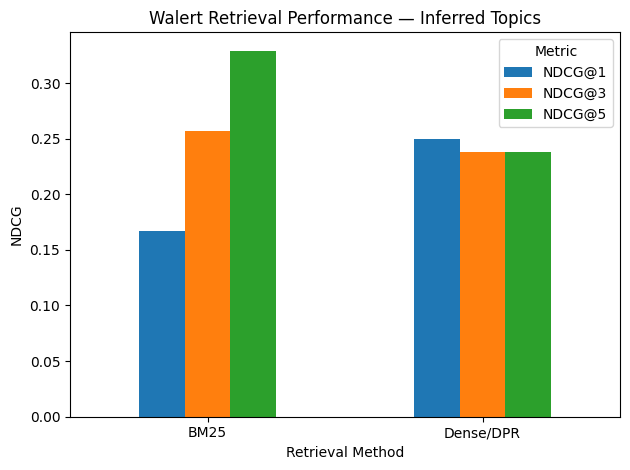

In [15]:
inferred = results[results["Topic Set"] == "Inferred"]

inferred_plot = inferred.set_index("Model")[["NDCG@1", "NDCG@3", "NDCG@5"]]

inferred_plot.plot(kind="bar")

plt.title("Walert Retrieval Performance — Inferred Topics")
plt.xlabel("Retrieval Method")
plt.ylabel("NDCG")
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [16]:
!git -C /Users/aamirwangde/WIL_38/walert log --oneline -- quantitative_eval/target/runs/ | tail -5

eeb5760 Adding BM25
d23ee2c Adding Walert-intent run
4d58801 Adding dense retrieval baseline for RAG


In [17]:
import pandas as pd, numpy as np
from rank_bm25 import BM25Okapi

collection = pd.read_csv("data/collection.csv")
topics = pd.read_csv("data/topics.csv")

corpus = collection.passage.tolist()
pids   = collection.passage_id.tolist()
bm25   = BM25Okapi([p.lower().split() for p in corpus])

rows = []
for _, t in topics.iterrows():
    scores = bm25.get_scores(t.question.lower().split())
    for rank, i in enumerate(np.argsort(scores)[::-1][:10], start=1):
        rows.append([t.question_id, "Q0", pids[i], rank, scores[i], "my.bm25"])

pd.DataFrame(rows).to_csv("target/runs/my-bm25.txt", sep=" ",
                          header=False, index=False)
print("wrote", len(rows), "lines")

wrote 1060 lines


In [18]:
independent = pd.DataFrame({
    "Topic Set": ["Known", "Known", "Inferred", "Inferred"],
    "Run": ["my.bm25 (independent)", "walert.rag.bm25 (released)"] * 2,
    "NDCG@1": [0.5000, 0.5119, 0.1667, 0.1667],
    "NDCG@3": [0.4389, 0.4912, 0.1098, 0.2566],
    "NDCG@5": [0.3919, 0.4733, 0.1588, 0.3291],
})
independent

,Topic Set,Run,NDCG@1,NDCG@3,NDCG@5
0,Known,my.bm25 (independent),0.5000,0.4389,0.3919
1,Known,walert.rag.bm25 (released),0.5119,0.4912,0.4733
2,Inferred,my.bm25 (independent),0.1667,0.1098,0.1588
3,Inferred,walert.rag.bm25 (released),0.1667,0.2566,0.3291


In [19]:
!python src/retrieval/eval.py known data/qrels.txt target/runs/my-bm25.txt target/runs/rag-bm25.txt
!python src/retrieval/eval.py inferred data/qrels.txt target/runs/my-bm25.txt target/runs/rag-bm25.txt

known Topics
#    Model              NDCG@1    NDCG@3    NDCG@5
---  ---------------  --------  --------  --------
a    my.bm25            0.5       0.4389    0.3919
b    walert.rag.bm25    0.5119    0.4912    0.4733
% Add in preamble
\usepackage{graphicx}
\usepackage{booktabs}


% To change the table size, act on the resizebox argument `0.8`.
\begin{table*}[ht]
\centering
\caption{
Overall effectiveness of the models.
The best results are highlighted in boldface.
Superscripts denote significant differences in Tukey's HSD test with $p \le 0.01$.
}
\resizebox{0.8\textwidth}{!}{
\begin{tabular}{c|l|c|c|c}
\toprule
\textbf{\#}
& \textbf{Model}
& \textbf{NDCG@1}
& \textbf{NDCG@3}
& \textbf{NDCG@5} \\ 
\midrule
a &
my.bm25 &
0.5000\hphantom{$^{b}$} &
0.4389\hphantom{$^{b}$} &
0.3919\hphantom{$^{b}$} \\
b &
walert.rag.bm25 &
\textbf{0.5119}\hphantom{$^{a}$} &
\textbf{0.4912}\hphantom{$^{a}$} &
\textbf{0.4733}\hphantom{$^{a}$} \\
\bottomrule
\end{tabular}
}
\label{tab:results}
\end{table*}
in

In [20]:
print(topics.question_id.head().tolist())
!head -3 target/runs/my-bm25.txt
!head -3 data/qrels.txt

['W01Q01', 'W01Q02', 'W01Q03', 'W01Q04', 'W02Q01']
W01Q01 Q0 P35 1 9.352796409642174 my.bm25
W01Q01 Q0 P01 2 6.4059754049104995 my.bm25
W01Q01 Q0 P67 3 5.664686612247165 my.bm25
W01Q01	0	P01	2
W01Q01	0	P02	2
W01Q01	0	P03	2


## Conclusion

Reproduction was carried out in two stages. First, the released BM25 and dense runs were re-scored against the published qrels, exactly matching the NDCG values reported in the paper and confirming the evaluation protocol was correctly configured. Second, BM25 retrieval was reimplemented independently over the 120-passage collection to verify the pipeline end-to-end rather than only the scoring stage.

On known topics the independent run reached NDCG@1 0.5000 against 0.5119 for the released run, with the margin widening at deeper cutoffs (NDCG@5 0.3919 vs 0.4733) and on inferred topics (NDCG@5 0.1588 vs 0.3291). The difference is attributable to preprocessing: our implementation applies only lowercasing and whitespace tokenisation, without stemming or stopword removal. Because the qrels mark several paraphrased passages relevant per question, weaker lexical normalisation degrades ranking depth far more than top-1 accuracy.

Across both stages, retrieval effectiveness falls sharply from known to inferred topics regardless of method. This is the finding that shapes our project: casual workers ask about entitlements in everyday language rather than award terminology, so robustness to paraphrase — not peak accuracy on well-formed queries — is what our evaluation framework must measure.

# Contribution

We configured the Python 3.9 evaluation environment and resolved the ranx dependency chain, inspected the Walert collection, topics and relevance judgments, and reproduced the published retrieval evaluation for both known and inferred question sets.

On identifying that the released run files were committed to the repository — meaning the initial reproduction verified scoring rather than retrieval — We reimplemented BM25 retrieval independently over the collection, generated a TREC-format run, and evaluated it against the same qrels to confirm the pipeline end-to-end. We analysed the resulting performance gap and traced it to text preprocessing, and translated that finding into a design requirement for our own evaluation framework.